# 1982 — Self-Organizing Maps (Kohonen)

**Paper:** Teuvo Kohonen, *"Self-organized formation of topologically correct feature maps"* (1982).

An **unsupervised**, competitive network. Neurons sit on a 2-D grid, each with a weight vector in input space. For each input $x$:

1. find the **best-matching unit** $c = \arg\min_j \|x - w_j\|$
2. pull it *and its grid neighbours* toward $x$: $\;w_j \leftarrow w_j + \eta(t)\, h_{cj}(t)\,(x - w_j)$, with $h_{cj} = \exp(-\|r_c - r_j\|^2 / 2\sigma(t)^2)$

Both $\eta$ and $\sigma$ shrink over time. Result: a **topology-preserving map** — similar inputs land on nearby neurons (like maps in the visual cortex).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

In [2]:
class SOM:
    def __init__(self, rows, cols, dim):
        self.W = rng.random((rows, cols, dim))
        self.grid = np.stack(np.meshgrid(np.arange(rows), np.arange(cols), indexing="ij"), -1).astype(float)

    def bmu(self, x):
        d = ((self.W - x) ** 2).sum(-1)
        return np.unravel_index(d.argmin(), d.shape)

    def train(self, X, steps=6000, lr0=0.5, sigma0=None):
        sigma0 = sigma0 or max(self.W.shape[:2]) / 2
        for t in range(steps):
            frac = t / steps
            lr, sigma = lr0 * (1 - frac) + 0.01, sigma0 * (0.5 / sigma0) ** frac   # both decay over time
            x = X[rng.integers(len(X))]
            c = np.array(self.bmu(x))
            h = np.exp(-((self.grid - c) ** 2).sum(-1) / (2 * sigma ** 2))[..., None]
            self.W += lr * h * (x - self.W)

## Organising random colours
Inputs are RGB colours. After training, the 2-D grid *is* a smooth colour map.

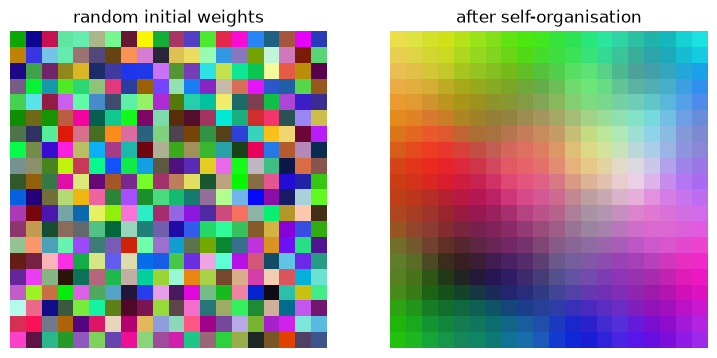

In [3]:
colors = rng.random((500, 3))
som = SOM(20, 20, 3)
before = som.W.copy()
som.train(colors)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(before); axes[0].set_title("random initial weights")
axes[1].imshow(som.W); axes[1].set_title("after self-organisation")
for a in axes: a.axis("off")
plt.show()

## U-matrix: where are the cluster borders?
The average distance between each neuron and its neighbours — high values mark boundaries between regions.

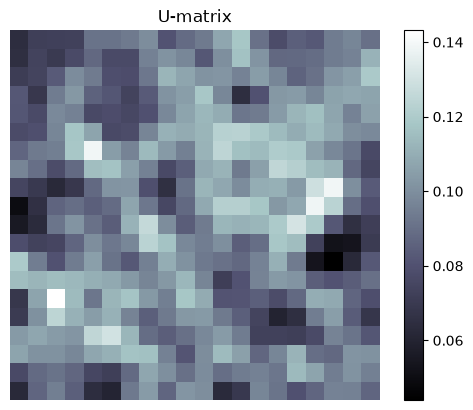

In [4]:
R, C, _ = som.W.shape
U = np.zeros((R, C))
for i in range(R):
    for j in range(C):
        nb = [som.W[a, b] for a, b in [(i-1, j), (i+1, j), (i, j-1), (i, j+1)] if 0 <= a < R and 0 <= b < C]
        U[i, j] = np.mean([np.linalg.norm(som.W[i, j] - w) for w in nb])
plt.imshow(U, cmap="bone"); plt.colorbar(); plt.title("U-matrix"); plt.axis("off"); plt.show()

## Mapping digits to the grid
Train on the 64-pixel handwritten digits; each digit class occupies its own region of the map, without ever seeing a label.

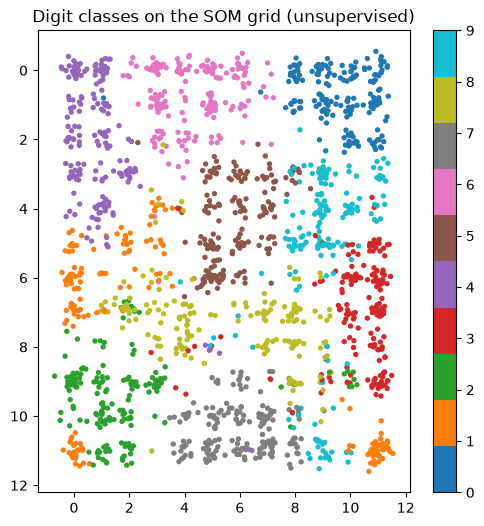

In [5]:
from sklearn.datasets import load_digits
d = load_digits()
Xd = d.data / 16.0
som_d = SOM(12, 12, 64)
som_d.train(Xd, steps=8000, lr0=0.5, sigma0=6)
pos = np.array([som_d.bmu(x) for x in Xd]).astype(float) + rng.normal(0, 0.2, (len(Xd), 2))
plt.figure(figsize=(6, 6))
sc = plt.scatter(pos[:, 1], pos[:, 0], c=d.target, cmap="tab10", s=8)
plt.colorbar(sc, ticks=range(10)); plt.gca().invert_yaxis(); plt.title("Digit classes on the SOM grid (unsupervised)"); plt.show()